In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score

rng = np.random.default_rng(0)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
H = pd.Timedelta

# -- plotting style (same palette as the course tutorials) ---------------------------
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, RED = "#2a78d6", "#eb6834", "#e34948"   # series / fit / negative
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": BASELINE, "axes.labelcolor": INK2,
    "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "font.family": "sans-serif", "figure.dpi": 110,
})
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.5.5 | pandas 3.1.1


# Project — Personalized meal-insulin dosing in Type 1 Diabetes
**Notebook 2 — Linear regression of the meal bolus (AZT1D)**

Notebook 1 built a table with one row per meal episode: pre-meal features, the manual bolus $y$ (U) the patient took,
and the post-meal outcome. Here we fit and evaluate linear models of $y$ on the meals whose dose **worked** (clean
post-meal window, no hypoglycaemia, glucose in 70–180 mg/dL three hours later).

The notebook answers three questions:

1. **Population model.** Can one linear model, fitted on everybody, predict the dose of a patient from the meal, the
   glucose context and the profile (age, sex, HbA1c) — without any history of that patient?
2. **Personal history.** How much does the patient's own dosing history help, and how much history should be used?
3. **Context on top of history.** Once the history is used, does a multivariable linear model with the meal context
   (glucose level and trend, insulin on board, time of day, exercise, …) improve the prediction further?

> **Leakage rules.** (i) Features use only information available before the meal $t_0$. (ii) Every modelling choice —
> history window, regularization strength, imputation values, scaling — is made on the **training split only**.
> (iii) Post-meal outcomes select rows; they are never features.

## 1. Load the meal table

In [2]:
DATA = Path("data/processed/azt1d_meal_episodes.csv")
assert DATA.exists(), "run 01_preprocessing.ipynb first"

episodes = (pd.read_csv(DATA, parse_dates=["t0", "t1"])
              .sort_values(["pid", "t0"]).reset_index(drop=True))
print(f"{len(episodes):,} meal episodes from {episodes.pid.nunique()} patients | "
      f"training candidates (usable dose, complete CGM, clean, good): {episodes.train_candidate.sum():,}")

3,743 meal episodes from 24 patients | training candidates (usable dose, complete CGM, clean, good): 907


## 2. The personal insulin-to-carbohydrate ratio is a linear regression

The pump's bolus calculator computes
$$
\text{dose} \;=\; \frac{\text{carbs}}{\text{ICR}} \;+\; \frac{G - G_{\text{target}}}{\text{ISF}} \;-\; \text{IOB},
$$
with two **patient-specific** settings: the insulin-to-carbohydrate ratio ICR (g of carbohydrate covered by 1 U) and the
insulin sensitivity factor ISF (mg/dL lowered by 1 U). Neither is in the data, and the profile (age, sex, HbA1c) does not
determine them. But each patient's **history** does.

**Personal model.** For patient $p$, assume the dose is proportional to the carbohydrates, with a noise whose variance
grows with the meal size:
$$
y_i = r_p\, c_i + \varepsilon_i, \qquad \operatorname{Var}(\varepsilon_i) \propto c_i ,
$$
where $r_p = 1/\text{ICR}_p$ (U/g). This is a **linear regression without intercept**, fitted by weighted least squares
with weights $1/c_i$ on the patient's previous meals $\mathcal{P}$:
$$
\hat r_p = \arg\min_r \sum_{i\in\mathcal{P}} \frac{(y_i - r\,c_i)^2}{c_i}
\quad\Longrightarrow\quad
-2\sum_{i\in\mathcal{P}} (y_i - r\,c_i) = 0
\quad\Longrightarrow\quad
\boxed{\;\hat r_p = \frac{\sum_{i\in\mathcal{P}} y_i}{\sum_{i\in\mathcal{P}} c_i}\;}
$$
— the **ratio estimator**: total insulin over total carbohydrates. Its prediction for a new meal is
$\hat y = \hat r_p \cdot \text{carbs}$.

**Which meals form $\mathcal{P}$?** Only meals **before** $t_0$ (so the estimate never sees the future), and either the
whole history or only the **last $W$ meals** — a short window follows changes in the patient's settings over the weeks,
a long one averages out noise. Variant: use only previous *good & clean* meals (the doses that worked), which is fewer
meals but possibly less biased.

In [3]:
def personal_ratio(ep, window=None, only_good=False):
    """Ratio estimator sum(dose) / sum(carbs) over each patient's PREVIOUS usable meals.

    ep        : all meal episodes, RangeIndex, sorted by (pid, t0)
    window    : use only the last `window` previous meals (None = whole history)
    only_good : use only previous clean & good meals whose outcome was already known at t0
    """
    out = np.full(len(ep), np.nan)
    for pid, x in ep.groupby("pid"):
        pos = x.index.to_numpy()
        t0 = x.t0.to_numpy()
        use = x.usable_dose.to_numpy()
        avail = t0                                           # a previous meal is usable once it happened...
        if only_good:
            use = use & (x.good & x.clean_strict & x.cgm_ok).to_numpy()
            avail = (x.t1 + H("3h")).to_numpy()              # ...or once its 3-h outcome is known
        dose, carbs = x.dose_u.to_numpy(), x.carbs_g.to_numpy()
        for k in range(len(x)):
            past = np.flatnonzero(use & (avail < t0[k]))
            if window is not None:
                past = past[-window:]
            if len(past):
                out[pos[k]] = dose[past].sum() / carbs[past].sum()
    return out


WINDOWS = [5, 10, 20, 40, None]                              # None = whole history
for w in WINDOWS:
    episodes[f"r_{w or 'all'}"] = personal_ratio(episodes, window=w)
    episodes[f"r_good_{w or 'all'}"] = personal_ratio(episodes, window=w, only_good=True)

# 🧪 test: the whole-history estimate must equal `hist_ratio` computed independently in Notebook 1
assert np.allclose(episodes["r_all"], episodes["hist_ratio"], equal_nan=True)
print("ratio estimator matches Notebook 1 ✓")
print("personal ratio (U/g), whole history:", episodes.r_all.describe()[["mean", "min", "50%", "max"]].round(3).to_dict(),
      f"-> ICR between {1 / episodes.r_all.max():.0f} and {1 / episodes.r_all.min():.0f} g/U")

ratio estimator matches Notebook 1 ✓
personal ratio (U/g), whole history: {'mean': 0.184, 'min': 0.067, '50%': 0.123, 'max': 0.518} -> ICR between 2 and 15 g/U


**The ratio drifts over time.** For three patients, the whole-history estimate (smooth) and the last-20-meals estimate
(responsive) over the follow-up. When a patient's settings or habits change, the whole-history average lags behind.

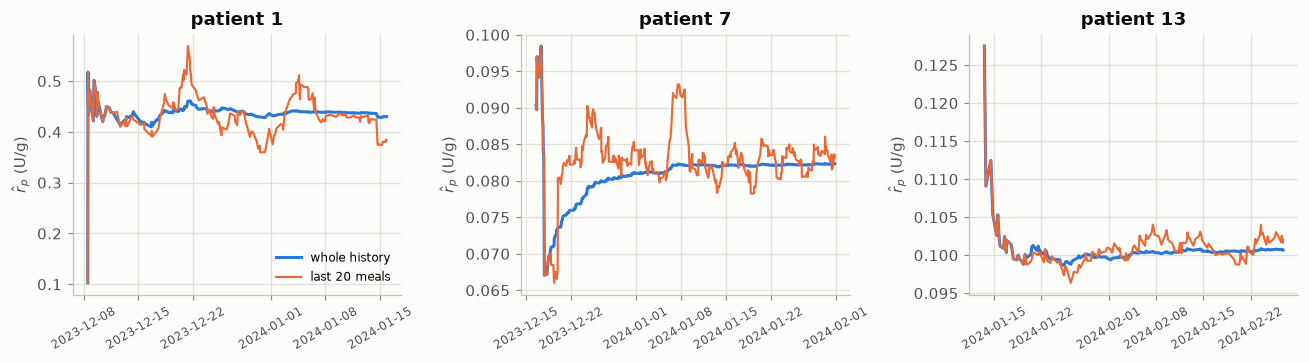

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=False)
for ax, pid in zip(axes, [1, 7, 13]):
    x = episodes[episodes.pid == pid]
    ax.plot(x.t0, x.r_all, color=BLUE, lw=2, label="whole history")
    ax.plot(x.t0, x.r_20, color=ORANGE, lw=1.4, label="last 20 meals")
    ax.set_title(f"patient {pid}")
    ax.set_ylabel(r"$\hat r_p$ (U/g)")
    ax.tick_params(axis="x", labelrotation=30, labelsize=8)
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

## 3. Rows and temporal split within each patient

**Rows.** Training candidates from Notebook 1 (usable dose, complete CGM, clean window, good outcome) with at least
`MIN_HISTORY` = 10 previous meals, so that every patient has a history before being modelled.

**Split.** The model is used *on a patient it already knows*, so we split **in time within each patient**: the first 70 %
of a patient's meals are training, the last 30 % are test. Every patient appears in both sets, and every test meal is
later than every training meal of the same patient — the test set imitates "the next weeks".

rows: 840 from 24 patients -> train 582 | test 258


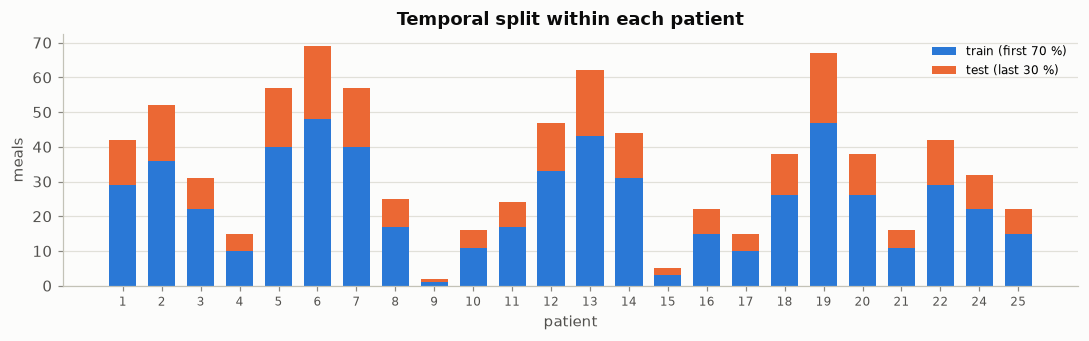

In [5]:
MIN_HISTORY, TRAIN_FRAC = 10, 0.7

rows = episodes[episodes.train_candidate & (episodes.hist_n_meals >= MIN_HISTORY)].copy()
rows = rows.join(rows.groupby("pid")["t0"].quantile(TRAIN_FRAC).rename("t_cut"), on="pid")
rows["split"] = np.where(rows.t0 <= rows.t_cut, "train", "test")
train, test = rows[rows.split == "train"].copy(), rows[rows.split == "test"].copy()

print(f"rows: {len(rows):,} from {rows.pid.nunique()} patients -> train {len(train):,} | test {len(test):,}")
counts = rows.groupby(["pid", "split"]).size().unstack(fill_value=0)[["train", "test"]]

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(counts.index.astype(str), counts.train, color=BLUE, width=0.7, label="train (first 70 %)")
ax.bar(counts.index.astype(str), counts.test, bottom=counts.train, color=ORANGE, width=0.7, label="test (last 30 %)")
ax.set_xlabel("patient"); ax.set_ylabel("meals")
ax.set_title("Temporal split within each patient")
ax.legend(frameon=False, fontsize=8); ax.grid(axis="x", visible=False); ax.tick_params(axis="x", labelsize=8)
plt.tight_layout()
plt.show()

## 4. Exploration — training split only

**Dose vs carbohydrates per patient.** Within a patient the relation is close to a line through the origin; **across**
patients the slopes differ several-fold — which is why one population slope cannot work.

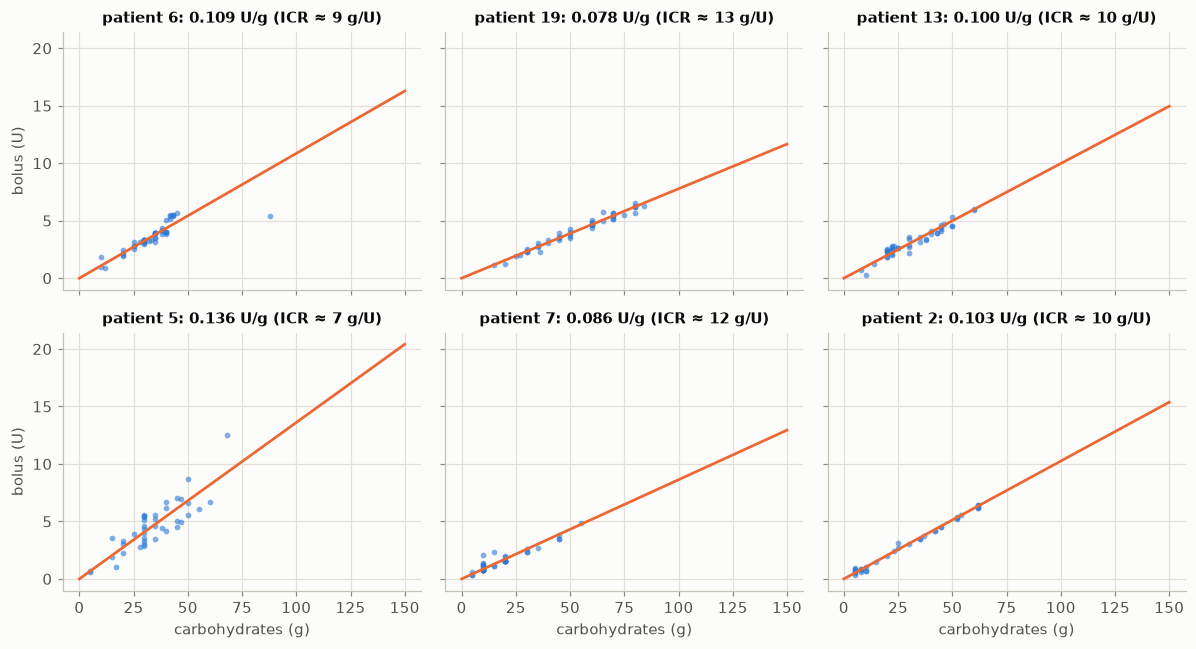

In [6]:
top6 = train.pid.value_counts().index[:6]
fig, axes = plt.subplots(2, 3, figsize=(11, 6), sharex=True, sharey=True)
for ax, pid in zip(axes.ravel(), top6):
    x = train[train.pid == pid]
    slope = x.dose_u.sum() / x.carbs_g.sum()                       # ratio estimator on the training meals
    grid = np.linspace(0, train.carbs_g.max(), 50)
    ax.scatter(x.carbs_g, x.dose_u, s=14, color=BLUE, alpha=0.6, linewidths=0)
    ax.plot(grid, slope * grid, color=ORANGE, lw=1.8)
    ax.set_title(f"patient {pid}: {slope:.3f} U/g (ICR ≈ {1 / slope:.0f} g/U)", fontsize=10)
for ax in axes[-1]: ax.set_xlabel("carbohydrates (g)")
for ax in axes[:, 0]: ax.set_ylabel("bolus (U)")
plt.tight_layout()
plt.show()

**Correlation of each feature with the dose** (training split). `x_food` is the personal prediction
$\hat r_p \cdot \text{carbs}$ with the last-20-meals ratio; everything else is a raw feature from Notebook 1.

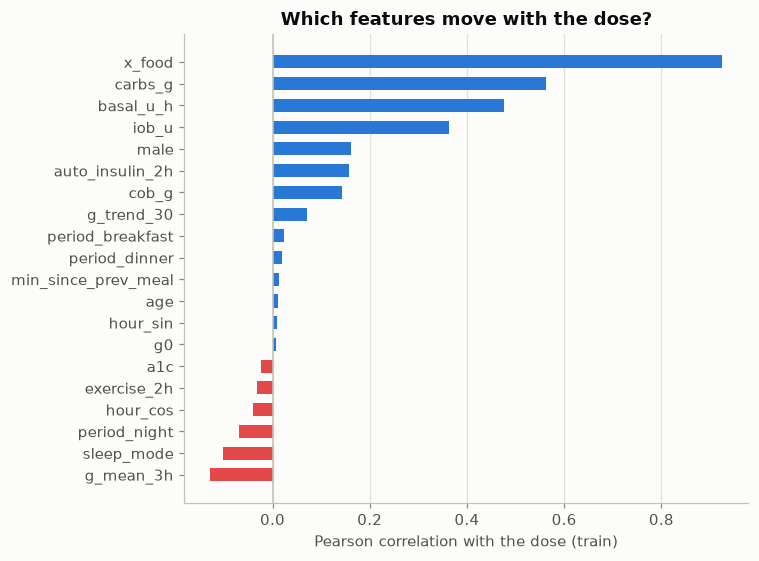

In [7]:
CONTEXT = ["g0", "g_trend_30", "g_mean_3h", "iob_u", "cob_g", "min_since_prev_meal", "auto_insulin_2h",
           "basal_u_h", "hour_sin", "hour_cos", "period_breakfast", "period_dinner", "period_night",
           "exercise_2h", "sleep_mode"]
PROFILE = ["age", "male", "a1c"]

corr = (train.assign(x_food=train.carbs_g * train.r_20)[["x_food", "carbs_g"] + CONTEXT + PROFILE]
             .corrwith(train.dose_u).sort_values())
fig, ax = plt.subplots(figsize=(7, 5.2))
ax.barh(corr.index, corr.values, color=[BLUE if v > 0 else RED for v in corr.values], height=0.6)
ax.axvline(0, color=BASELINE, lw=1)
ax.set_xlabel("Pearson correlation with the dose (train)")
ax.set_title("Which features move with the dose?")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 5. Models

| | Model | Uses the patient's history? | Fitted on |
|---|---|---|---|
| **B0** | patient's mean training dose | yes (mean only) | train |
| **M1** | **population** linear regression: carbs + context + profile | no | train, all patients pooled |
| **M2** | **personal ratio**: $\hat y = \hat r_p\cdot \text{carbs}$ (per-patient regression through the origin, §2) | yes | the patient's previous meals |
| **M3** | **personalized multivariable** linear regression: M2's terms + context + profile | yes | train, all patients pooled |

**M3 in detail.** Two features carry the personal ratio into one pooled model:
$$
x_{\text{food}} = \hat r_p \cdot \text{carbs}, \qquad
x_{\text{corr}} = \hat r_p \cdot \max(g_0 - 110,\, 0),
$$
the second one because a patient who needs more insulin per gram is usually also more insulin-resistant
($\text{ISF} \propto \text{ICR}$ in the classic "500 / 1800" clinical rules of thumb), so the correction should scale
with the same ratio. If the model rediscovered the calculator, $\beta_{\text{food}} \approx 1$.

Two fits of M3:
* **M3-OLS** — ordinary least squares on all features;
* **M3-ridge** — ridge regression on the **residual of M2**, $y - x_{\text{food}}$, with standardized features and the
  penalty $\alpha$ chosen by cross-validation on the training split. Shrinking the coefficients towards zero then means
  *falling back to the personal rule*: context only enters if it pays off.

**Training details (all estimated on the training split):** missing basal rates are imputed with the training median;
each patient gets the same total weight ($w_i = 1/n_p$), so patients with many meals do not dominate.

**Metric.** The primary metric is the **per-patient MAE averaged over patients** (pMAE, in units of insulin): every
patient counts the same, like the weights. We also report pooled MAE, RMSE, $R^2$ and the share of meals predicted
within ±1 U.

In [8]:
G_TARGET = 110                                   # typical correction target (mg/dL)


def add_personal(df, r):
    df = df.copy()
    df["ratio"] = df[r]
    df["x_food"] = df.carbs_g * df.ratio
    df["x_corr"] = (df.g0 - G_TARGET).clip(lower=0) * df.ratio
    return df


def metrics(df, pred):
    err = df.dose_u.to_numpy() - np.asarray(pred)
    per_pid = pd.Series(np.abs(err), index=df.index).groupby(df.pid).mean()
    return {"pMAE": per_pid.mean(), "MAE": np.abs(err).mean(), "RMSE": np.sqrt((err ** 2).mean()),
            "R2": r2_score(df.dose_u, pred), "within_1U": (np.abs(err) <= 1).mean()}


def per_patient_mae(df, pred):
    return pd.Series(np.abs(df.dose_u.to_numpy() - np.asarray(pred)), index=df.index).groupby(df.pid).mean()


def patient_weights(df):
    return (1 / df.groupby("pid")["pid"].transform("size")).to_numpy()

### 5.1 Choosing the history window — on the training split

The ratio predictions on the training meals are already out-of-sample (they use only earlier meals), so the window can
be chosen by its pMAE on the **training** rows. The test split stays untouched.

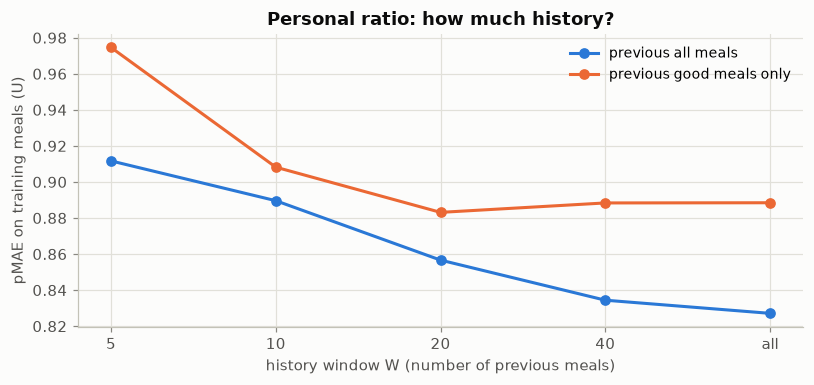

window         history     column  train_pMAE  coverage
     5       all meals        r_5       0.912     1.000
     5 good meals only   r_good_5       0.975     0.997
    10       all meals       r_10       0.890     1.000
    10 good meals only  r_good_10       0.908     0.997
    20       all meals       r_20       0.857     1.000
    20 good meals only  r_good_20       0.883     0.997
    40       all meals       r_40       0.834     1.000
    40 good meals only  r_good_40       0.888     0.997
   all       all meals      r_all       0.827     1.000
   all good meals only r_good_all       0.888     0.997

chosen on TRAIN: r_all (window all, all meals) -> train pMAE 0.827 U


In [9]:
choices = []
for w in WINDOWS:
    for good in (False, True):
        col = f"r_{'good_' if good else ''}{w or 'all'}"
        ok = train[col].notna()
        choices.append({"window": w or "all", "history": "good meals only" if good else "all meals",
                        "column": col, "train_pMAE": metrics(train[ok], train.carbs_g[ok] * train[col][ok])["pMAE"],
                        "coverage": ok.mean()})
choices = pd.DataFrame(choices)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
for (hist, grp), color in zip(choices.groupby("history", sort=False), [BLUE, ORANGE]):
    ax.plot(grp.window.astype(str), grp.train_pMAE, "o-", color=color, lw=2, label=f"previous {hist}")
ax.set_xlabel("history window W (number of previous meals)")
ax.set_ylabel("pMAE on training meals (U)")
ax.set_title("Personal ratio: how much history?")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

best = choices.loc[choices.train_pMAE.idxmin()]
R_COL = best.column
print(choices.round(3).to_string(index=False))
print(f"\nchosen on TRAIN: {R_COL} (window {best.window}, {best.history}) -> train pMAE {best.train_pMAE:.3f} U")

### 5.2 Fitting the four models

In [10]:
tr, te = add_personal(train, R_COL), add_personal(test, R_COL)
w_tr = patient_weights(tr)
preds = {}

# B0 — patient's mean training dose
pmean = tr.groupby("pid").dose_u.mean()
preds["B0  patient mean dose"] = te.pid.map(pmean)

# M1 — population linear regression (no history)
F_M1 = ["carbs_g"] + CONTEXT + PROFILE
med_m1 = tr[F_M1].median()
m1 = LinearRegression().fit(tr[F_M1].fillna(med_m1), tr.dose_u, sample_weight=w_tr)
preds["M1  population linear"] = m1.predict(te[F_M1].fillna(med_m1))

# M2 — personal ratio (regression through the origin on the patient's previous meals)
preds["M2  personal ratio"] = te.x_food

# M3 — personalized multivariable linear regression
F_M3 = ["x_food", "x_corr"] + CONTEXT + PROFILE
med_m3 = tr[F_M3].median()
X_tr, X_te = tr[F_M3].fillna(med_m3), te[F_M3].fillna(med_m3)

m3_ols = LinearRegression().fit(X_tr, tr.dose_u, sample_weight=w_tr)
preds["M3  personalized linear (OLS)"] = m3_ols.predict(X_te)

m3_ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 49)))
m3_ridge.fit(X_tr, tr.dose_u - tr.x_food, ridgecv__sample_weight=w_tr)            # residual of M2
preds["M3  personalized linear (ridge on M2 residual)"] = te.x_food + m3_ridge.predict(X_te)
print(f"ridge alpha chosen by CV on train: {m3_ridge[-1].alpha_:.3g}")

ridge alpha chosen by CV on train: 3.16


## 6. Results on the test split

The confidence intervals resample **patients** (bootstrap, 2,000 draws): with 24 patients, the uncertainty that matters
is "which patients happened to be in the study".

,pMAE,MAE,RMSE,R2,within_1U,pMAE_lo,pMAE_hi
model,,,,,,,
B0 patient mean dose,2.26,2.19,3.25,0.64,37%,1.57,3.10
M1 population linear,2.46,2.27,3.18,0.65,34%,1.88,3.11
M2 personal ratio,0.80,0.82,1.97,0.87,81%,0.44,1.26
M3 personalized linear (OLS),0.84,0.83,1.79,0.89,84%,0.53,1.25
M3 personalized linear (ridge on M2 residual),0.80,0.81,1.77,0.89,83%,0.48,1.18


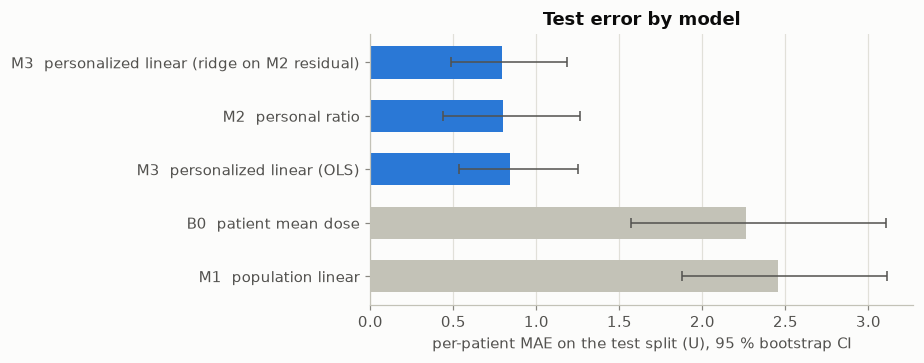

test meals: 258 | median dose 4.0 U


In [11]:
def bootstrap_pmae(per_pid, n=2000):
    v = per_pid.to_numpy()
    draws = rng.choice(v, size=(n, len(v)), replace=True).mean(axis=1)
    return np.percentile(draws, [2.5, 97.5])


results = []
for name, p in preds.items():
    m = metrics(te, p)
    lo, hi = bootstrap_pmae(per_patient_mae(te, p))
    results.append({"model": name, **m, "pMAE_lo": lo, "pMAE_hi": hi})
results = pd.DataFrame(results).set_index("model")
display(results.style.format({"pMAE": "{:.2f}", "MAE": "{:.2f}", "RMSE": "{:.2f}", "R2": "{:.2f}",
                              "within_1U": "{:.0%}", "pMAE_lo": "{:.2f}", "pMAE_hi": "{:.2f}"}))

fig, ax = plt.subplots(figsize=(8.5, 3.4))
order = results.pMAE.sort_values(ascending=False)
ypos = np.arange(len(order))
colors = [BLUE if n.startswith("M2") or n.startswith("M3") else BASELINE for n in order.index]
ax.barh(ypos, order.values, color=colors, height=0.6)
ax.errorbar(order.values, ypos, xerr=[order.values - results.loc[order.index, "pMAE_lo"],
                                      results.loc[order.index, "pMAE_hi"] - order.values],
            fmt="none", ecolor=INK2, capsize=3, lw=1)
ax.set_yticks(ypos, order.index)
ax.set_xlabel("per-patient MAE on the test split (U), 95 % bootstrap CI")
ax.set_title("Test error by model")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
print(f"test meals: {len(te)} | median dose {te.dose_u.median():.1f} U")

**Patient by patient.** Does M3-ridge improve on the personal ratio M2 for most patients, or only on average? A
Wilcoxon signed-rank test compares the paired per-patient errors.

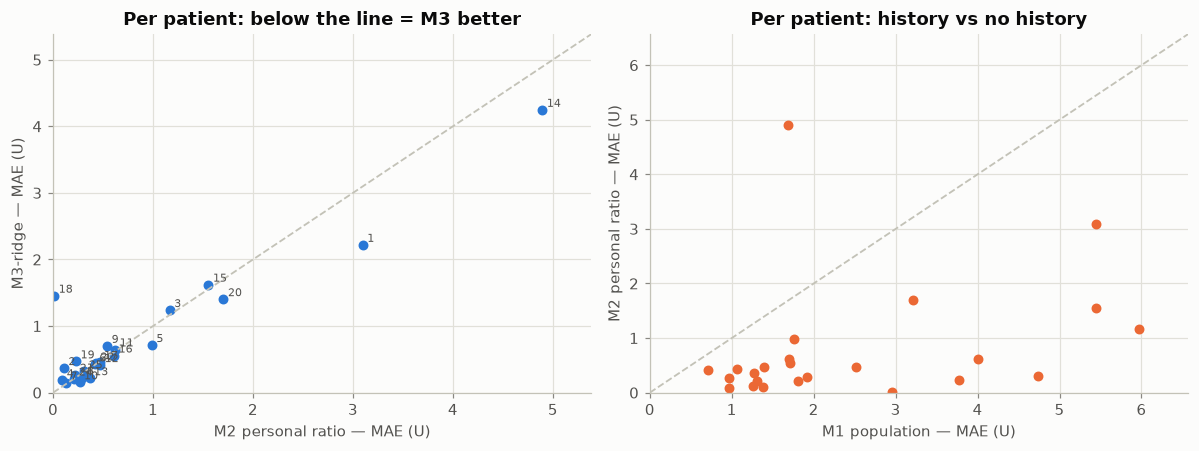

M3-ridge better than M2 for 10 of 24 patients | Wilcoxon p = 0.989
M2 better than M1 for 23 of 24 patients | Wilcoxon p = 3.7e-05


In [12]:
from scipy.stats import wilcoxon

e_m2 = per_patient_mae(te, preds["M2  personal ratio"])
e_m3 = per_patient_mae(te, preds["M3  personalized linear (ridge on M2 residual)"])
e_m1 = per_patient_mae(te, preds["M1  population linear"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
lim = max(e_m2.max(), e_m3.max()) * 1.1
ax1.plot([0, lim], [0, lim], color=BASELINE, lw=1.2, ls="--")
ax1.scatter(e_m2, e_m3, s=30, color=BLUE)
for pid in e_m2.index:
    ax1.annotate(str(pid), (e_m2[pid], e_m3[pid]), fontsize=7, color=INK2, xytext=(3, 2), textcoords="offset points")
ax1.set_xlim(0, lim); ax1.set_ylim(0, lim)
ax1.set_xlabel("M2 personal ratio — MAE (U)"); ax1.set_ylabel("M3-ridge — MAE (U)")
ax1.set_title("Per patient: below the line = M3 better")

ax2.scatter(e_m1, e_m2, s=30, color=ORANGE)
lim2 = max(e_m1.max(), e_m2.max()) * 1.1
ax2.plot([0, lim2], [0, lim2], color=BASELINE, lw=1.2, ls="--")
ax2.set_xlim(0, lim2); ax2.set_ylim(0, lim2)
ax2.set_xlabel("M1 population — MAE (U)"); ax2.set_ylabel("M2 personal ratio — MAE (U)")
ax2.set_title("Per patient: history vs no history")
plt.tight_layout()
plt.show()

stat, p = wilcoxon(e_m3, e_m2)
print(f"M3-ridge better than M2 for {(e_m3 < e_m2).sum()} of {len(e_m2)} patients | Wilcoxon p = {p:.3f}")
stat, p = wilcoxon(e_m2, e_m1)
print(f"M2 better than M1 for {(e_m2 < e_m1).sum()} of {len(e_m2)} patients | Wilcoxon p = {p:.2g}")

### 6.1 Error analysis: the patient with the largest error

One patient stands out in every model. Plotting the ratio of each of their meals over time shows why.

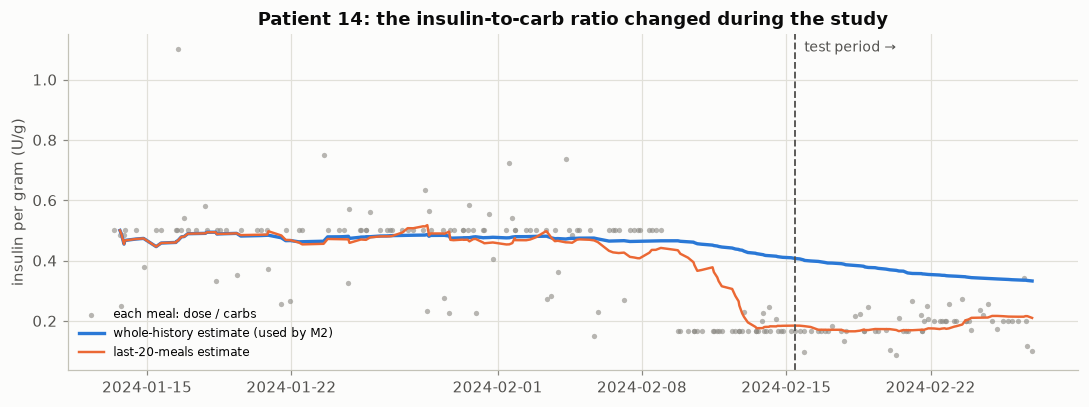

            meals  median U/g
week                         
2024-01-08    7.0       0.486
2024-01-15   24.0       0.500
2024-01-22   25.0       0.500
2024-01-29   33.0       0.500
2024-02-05   28.0       0.250
2024-02-12   39.0       0.167
2024-02-19   37.0       0.200
2024-02-26    5.0       0.200


In [13]:
worst = e_m2.idxmax()
x = episodes[(episodes.pid == worst) & episodes.usable_dose]
t_test = test[test.pid == worst].t0.min()

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.scatter(x.t0, x.dose_u / x.carbs_g, s=12, color=MUTED, alpha=0.6, linewidths=0, label="each meal: dose / carbs")
ax.plot(x.t0, x.r_all, color=BLUE, lw=2.2, label="whole-history estimate (used by M2)")
ax.plot(x.t0, x.r_20, color=ORANGE, lw=1.6, label="last-20-meals estimate")
ax.axvline(t_test, color=INK2, ls="--", lw=1.2)
ax.annotate("test period →", (t_test, ax.get_ylim()[1] * 0.95), xytext=(6, 0), textcoords="offset points",
            fontsize=9, color=INK2)
ax.set_ylabel("insulin per gram (U/g)")
ax.set_title(f"Patient {worst}: the insulin-to-carb ratio changed during the study")
ax.legend(frameon=False, fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

wk = x.assign(week=x.t0.dt.to_period("W").dt.start_time.dt.date).groupby("week").apply(
    lambda g: pd.Series({"meals": len(g), "median U/g": (g.dose_u / g.carbs_g).median()}), include_groups=False)
print(wk.round(3).to_string())

The patient's insulin-to-carbohydrate setting roughly **halved** between January and February (a change of pump
settings — the data cannot tell why). The whole-history estimate averages the old and new settings and lags behind.

**Post hoc — not used for any choice.** The table below shows what each history window *would* have scored on the test
split. The window was chosen on the training split (§5.1), where histories are still short (10–60 meals) and all windows
look alike; in the later test weeks, short windows win because they follow changes like this one. Choosing the window
on the test split would be leakage; the lesson for a real system is to **re-estimate the ratio continuously with a
recency window**, validated on a longer follow-up.

In [14]:
post = pd.DataFrame([{"window": w or "all",
                      "train pMAE (used for the choice)": choices.loc[choices.column == f"r_{w or 'all'}", "train_pMAE"].item(),
                      "test pMAE (post hoc)": metrics(test, test.carbs_g * test[f"r_{w or 'all'}"])["pMAE"]}
                     for w in WINDOWS]).set_index("window")
display(post.style.format("{:.3f}"))

,train pMAE (used for the choice),test pMAE (post hoc)
window,,
5,0.912,0.776
10,0.890,0.668
20,0.857,0.653
40,0.834,0.642
all,0.827,0.800


## 7. Interpreting M3: which context features matter?

Coefficients of **M3-OLS** in original units, with 95 % confidence intervals that are **cluster-robust by patient**
(meals of the same patient are not independent, so ordinary standard errors would be too optimistic). Weighted least
squares with the same patient weights, training split.

In [15]:
import statsmodels.api as sm

ols = sm.WLS(tr.dose_u, sm.add_constant(X_tr), weights=w_tr).fit(cov_type="cluster", cov_kwds={"groups": tr.pid})
coef = pd.DataFrame({"coef": ols.params, "ci_low": ols.conf_int()[0], "ci_high": ols.conf_int()[1],
                     "p_value": ols.pvalues}).drop("const")
coef["significant"] = coef.p_value < 0.05
display(coef.style.format({"coef": "{:.4f}", "ci_low": "{:.4f}", "ci_high": "{:.4f}", "p_value": "{:.3f}"}))
print(f"weighted R² (train) = {ols.rsquared:.3f}")

,coef,ci_low,ci_high,p_value,significant
x_food,0.9126,0.8680,0.9573,0.000,True
x_corr,0.1506,-0.0759,0.3771,0.192,False
g0,-0.0060,-0.0283,0.0164,0.601,False
g_trend_30,-0.0042,-0.0140,0.0057,0.404,False
g_mean_3h,-0.0084,-0.0177,0.0009,0.077,False
iob_u,-0.0502,-0.2105,0.1100,0.539,False
cob_g,0.0020,-0.0230,0.0271,0.874,False
min_since_prev_meal,0.0007,-0.0000,0.0014,0.061,False
auto_insulin_2h,-0.1440,-0.4193,0.1314,0.305,False
basal_u_h,-0.0721,-0.2935,0.1493,0.523,False


weighted R² (train) = 0.900


**Unit-free comparison.** Coefficients in original units cannot be compared (U per U, U per mg/dL, U per 0/1 flag…).
Multiplying each coefficient by the training standard deviation of its feature gives the change in dose (U) for a
one-standard-deviation change in the feature.

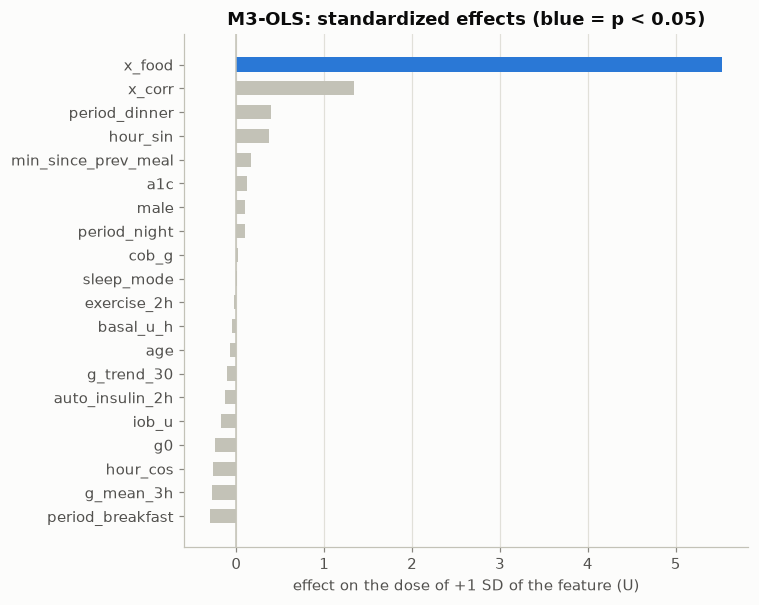

In [16]:
std_effect = (coef.coef * X_tr.std()).rename("U per 1 SD").sort_values()
fig, ax = plt.subplots(figsize=(7, 5.6))
sig = coef.loc[std_effect.index, "significant"]
ax.barh(std_effect.index, std_effect.values, color=[BLUE if s else BASELINE for s in sig], height=0.6)
ax.axvline(0, color=BASELINE, lw=1)
ax.set_xlabel("effect on the dose of +1 SD of the feature (U)")
ax.set_title("M3-OLS: standardized effects (blue = p < 0.05)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 8. Residual diagnostics of the personal ratio (M2)

Linear regression assumes residuals centred on zero with constant spread. With insulin doses we expect the spread to
grow with the dose (heteroscedasticity) — the assumption behind the $1/c_i$ weights in §2.

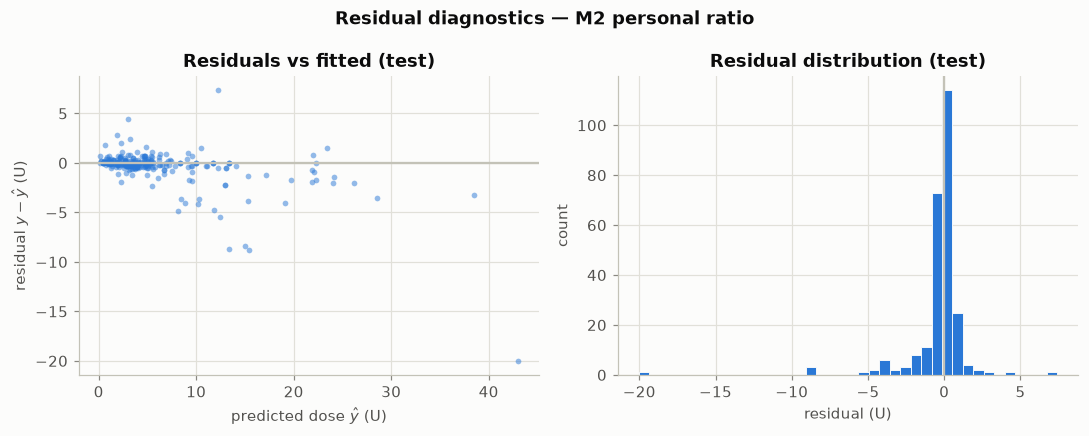

mean residual -0.37 U | residual SD for small predicted doses 0.69 U vs large 2.58 U | relative error (median |e|/y) 9%


In [17]:
yhat = np.asarray(preds["M2  personal ratio"])
resid = te.dose_u.to_numpy() - yhat

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.axhline(0, color=BASELINE, linewidth=1.5)
ax1.scatter(yhat, resid, s=14, color=BLUE, alpha=0.5, linewidths=0)
ax1.set_xlabel(r"predicted dose $\hat{y}$ (U)")
ax1.set_ylabel(r"residual $y - \hat{y}$ (U)")
ax1.set_title("Residuals vs fitted (test)")

ax2.hist(resid, bins=40, color=BLUE, edgecolor=SURFACE, linewidth=0.6)
ax2.axvline(0, color=BASELINE, linewidth=1.5)
ax2.set_xlabel("residual (U)"); ax2.set_ylabel("count")
ax2.set_title("Residual distribution (test)")
fig.suptitle("Residual diagnostics — M2 personal ratio", fontweight="bold", color=INK)
plt.tight_layout()
plt.show()

small, large = yhat < np.median(yhat), yhat >= np.median(yhat)
print(f"mean residual {resid.mean():+.2f} U | residual SD for small predicted doses {resid[small].std():.2f} U "
      f"vs large {resid[large].std():.2f} U | relative error (median |e|/y) {np.median(np.abs(resid) / te.dose_u):.0%}")

## 9. Sensitivity analyses

Each line changes one choice and repeats the pipeline (split, window, models) from scratch:

* **clean_manual** — allow automatic Control-IQ boluses after the meal (more rows, outcome partly due to the algorithm);
* **minimum history 5 / 20** previous meals instead of 10;
* **M3 trained on all clean meals** — good *and* bad outcomes — instead of good ones only (the test set stays the good
  meals: the doses that worked).

In [18]:
def run_setting(clean="clean_strict", min_hist=10, m3_on_all=False, r_col=R_COL):
    good_rows = (episodes.usable_dose & episodes.cgm_ok & episodes[clean] & episodes.good
                 & (episodes.hist_n_meals >= min_hist))
    rs = episodes[good_rows].copy()
    rs = rs.join(rs.groupby("pid")["t0"].quantile(TRAIN_FRAC).rename("t_cut"), on="pid")
    trn, tst = rs[rs.t0 <= rs.t_cut], rs[rs.t0 > rs.t_cut]
    if m3_on_all:                                       # same cut, but all clean meals in training
        allr = episodes[episodes.usable_dose & episodes.cgm_ok & episodes[clean] & (episodes.hist_n_meals >= min_hist)]
        allr = allr.join(rs.groupby("pid")["t0"].quantile(TRAIN_FRAC).rename("t_cut"), on="pid")
        trn = allr[allr.t0 <= allr.t_cut]
    trn, tst = add_personal(trn, r_col), add_personal(tst, r_col)
    w = patient_weights(trn)
    med = trn[F_M3].median()
    rid = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 49)))
    rid.fit(trn[F_M3].fillna(med), trn.dose_u - trn.x_food, ridgecv__sample_weight=w)
    ols_ = LinearRegression().fit(trn[F_M3].fillna(med), trn.dose_u, sample_weight=w)
    return {"test meals": len(tst), "patients": tst.pid.nunique(),
            "B0": metrics(tst, tst.pid.map(trn.groupby("pid").dose_u.mean()))["pMAE"],
            "M2": metrics(tst, tst.x_food)["pMAE"],
            "M3-OLS": metrics(tst, ols_.predict(tst[F_M3].fillna(med)))["pMAE"],
            "M3-ridge": metrics(tst, tst.x_food + rid.predict(tst[F_M3].fillna(med)))["pMAE"]}


settings = {"main (clean_strict, history ≥ 10)": {},
            "clean_manual": {"clean": "clean_manual"},
            "history ≥ 5": {"min_hist": 5},
            "history ≥ 20": {"min_hist": 20},
            "M3 trained on all clean meals": {"m3_on_all": True},
            }
ALT_R = "r_20" if R_COL != "r_20" else "r_all"                 # the other natural choice of history
settings[f"ratio {ALT_R} instead of {R_COL}"] = {"r_col": ALT_R}
sens = pd.DataFrame({name: run_setting(**kw) for name, kw in settings.items()}).T
display(sens.style.format({"B0": "{:.2f}", "M2": "{:.2f}", "M3-OLS": "{:.2f}", "M3-ridge": "{:.2f}",
                           "test meals": "{:.0f}", "patients": "{:.0f}"}))

,test meals,patients,B0,M2,M3-OLS,M3-ridge
"main (clean_strict, history ≥ 10)",258,24,2.26,0.80,0.84,0.80
clean_manual,384,24,2.34,0.78,0.79,0.77
history ≥ 5,262,24,2.27,0.80,0.83,0.79
history ≥ 20,239,23,2.33,0.77,0.86,0.83
M3 trained on all clean meals,258,24,2.25,0.80,0.86,0.82
ratio r_20 instead of r_all,258,24,2.26,0.65,0.77,0.70


## 10. Why a history is needed: the population model vs the number of patients

Could the population model M1 work if we simply had **more patients**? We train it on $k$ randomly chosen patients and
test it on all the others (40 random draws per $k$). This answers a different question from §6 — *new* patients instead
of *known* ones — so the dashed line (M2 on the temporal test split) is a reference, not a like-for-like comparison.

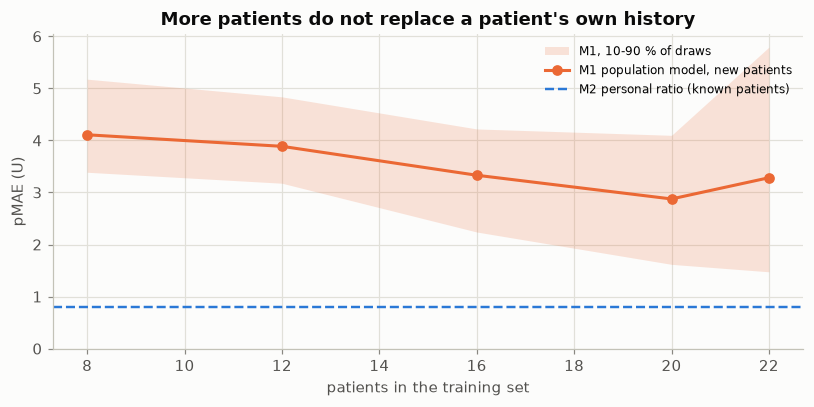

 k  mean  q10  q90
 8  4.11 3.39 5.18
12  3.89 3.18 4.84
16  3.33 2.24 4.22
20  2.88 1.62 4.10
22  3.28 1.48 5.79


In [19]:
pids = rows.pid.unique()
curve = []
for k in [8, 12, 16, 20, len(pids) - 2]:
    errs = []
    for _ in range(40):
        tr_p = rng.choice(pids, size=k, replace=False)
        a, b = rows[rows.pid.isin(tr_p)], rows[~rows.pid.isin(tr_p)]
        med = a[F_M1].median()
        m = LinearRegression().fit(a[F_M1].fillna(med), a.dose_u, sample_weight=patient_weights(a))
        errs.append(metrics(b, m.predict(b[F_M1].fillna(med)))["pMAE"])
    curve.append({"k": k, "mean": np.mean(errs), "q10": np.percentile(errs, 10), "q90": np.percentile(errs, 90)})
curve = pd.DataFrame(curve)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.fill_between(curve.k, curve.q10, curve.q90, color=ORANGE, alpha=0.18, lw=0, label="M1, 10-90 % of draws")
ax.plot(curve.k, curve["mean"], "o-", color=ORANGE, lw=2, label="M1 population model, new patients")
ax.axhline(results.loc["M2  personal ratio", "pMAE"], color=BLUE, ls="--", lw=1.6, label="M2 personal ratio (known patients)")
ax.set_xlabel("patients in the training set"); ax.set_ylabel("pMAE (U)")
ax.set_ylim(0, None)
ax.set_title("More patients do not replace a patient's own history")
ax.legend(frameon=False, fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()
print(curve.round(2).to_string(index=False))

## 11. Conclusions

The cell below prints the numbers quoted here.

1. **Without a patient's history, linear regression cannot dose.** The population model M1 (meal, glucose context,
   profile) has a per-patient MAE of **2.46 U** — no better than simply repeating the patient's mean dose (2.26 U), for
   a typical dose of 4 U. For *new* patients it stays around 3–4 U even with 16–22 training patients (§10). The
   insulin-to-carbohydrate ratio varies about seven-fold between patients (2–15 g/U), and age, sex and HbA1c do not
   predict it.
2. **The patient's own history is what works.** M2 — a per-patient linear regression through the origin on the
   previous meals — reaches **0.80 U** (95 % CI 0.44–1.26), $R^2 = 0.87$, with **81 % of the test meals within ±1 U**
   and a median relative error of 9 %. It beats the population model for 23 of 24 patients (Wilcoxon $p < 0.001$).
3. **The meal context adds no measurable information on top of the history.** The personalized multivariable model M3
   ties with M2 (ridge: 0.80 U, better for 10 of 24 patients, $p = 0.99$). In M3-OLS only $x_{\text{food}}$ is
   significant, with $\beta = 0.91$ (0.87–0.96): the model **rediscovers the bolus calculator**. Glucose level and
   trend, insulin on board, time of day, exercise and profile are all non-significant. Plausible reasons: these
   patients dose with a calculator that already accounts for glucose and insulin on board; on meals with a good outcome
   the correction is only a small share of the insulin; and exercise is rarely recorded (43 of 3,743 meals).
4. **The personal ratio drifts.** One patient halved their ratio during the study and the whole-history estimate lagged
   behind (§6.1). Post hoc, a 20–40-meal window would have lowered the test error to about 0.65 U — a hypothesis to
   validate on a longer follow-up, not a result of this study.
5. **The conclusions are robust** to the cleaning and history choices (§9).

**Limitations.** 24 patients followed for about six weeks. All use automated insulin delivery, which partly compensates
wrong doses, so a "good" outcome is not only the patient's merit. The label is the dose that was given, mostly computed
by the pump's calculator, so the models partly re-learn each patient's pump settings. Selecting good meals may favour
easier meals. Carbohydrates are the patients' own estimates, and there is no body weight, step count or heart rate.

**Next steps.** (i) Logistic regression of the risk of hypoglycaemia after a meal (Notebook 3); (ii) a
recency-weighted personal ratio chosen by nested temporal validation; (iii) external validation on HUPA-UCM, where
44 % of the patients use injections without a bolus calculator — the setting where a learned personal ratio is
actually useful; (iv) physiologically simulated data (UVA/Padova simulator) to study the *ideal* dose rather than the
dose taken.

In [20]:
r = results["pMAE"]
print(f"M1 population : {r['M1  population linear']:.2f} U  (patient mean dose B0: {r['B0  patient mean dose']:.2f} U)")
print(f"M2 personal   : {r['M2  personal ratio']:.2f} U  [{results.loc['M2  personal ratio', 'pMAE_lo']:.2f}, "
      f"{results.loc['M2  personal ratio', 'pMAE_hi']:.2f}] | R2 {results.loc['M2  personal ratio', 'R2']:.2f} "
      f"| within ±1 U: {results.loc['M2  personal ratio', 'within_1U']:.0%}")
print(f"M3 ridge      : {r['M3  personalized linear (ridge on M2 residual)']:.2f} U | M3 OLS: {r['M3  personalized linear (OLS)']:.2f} U")
print(f"x_food coefficient (M3-OLS): {coef.loc['x_food', 'coef']:.2f} [{coef.loc['x_food', 'ci_low']:.2f}, {coef.loc['x_food', 'ci_high']:.2f}]"
      f" | significant features: {coef.index[coef.significant].tolist()}")
print(f"correction share of the insulin in the modelling rows: {rows.dose_corr_u.sum() / rows.dose_u.sum():.0%}")
print(f"history window chosen on train: {R_COL} | best window post hoc on test: {post['test pMAE (post hoc)'].idxmin()} "
      f"({post['test pMAE (post hoc)'].min():.2f} U)")
print(f"sensitivity range of M2: {sens.M2.min():.2f}-{sens.M2.max():.2f} U | M3-ridge: {sens['M3-ridge'].min():.2f}-{sens['M3-ridge'].max():.2f} U")

M1 population : 2.46 U  (patient mean dose B0: 2.26 U)
M2 personal   : 0.80 U  [0.44, 1.26] | R2 0.87 | within ±1 U: 81%
M3 ridge      : 0.80 U | M3 OLS: 0.84 U
x_food coefficient (M3-OLS): 0.91 [0.87, 0.96] | significant features: ['x_food']
correction share of the insulin in the modelling rows: 8%
history window chosen on train: r_all | best window post hoc on test: 40 (0.64 U)
sensitivity range of M2: 0.65-0.80 U | M3-ridge: 0.70-0.83 U


## References

1. Khamesian S., Arefeen A., Thompson B. M., Grando M. A., Ghasemzadeh H. *AZT1D: A Real-World Dataset for Type 1
   Diabetes.* arXiv:2506.14789 (2025). Data: Mendeley Data, DOI
   [10.17632/gk9m674wcx.1](https://doi.org/10.17632/gk9m674wcx.1) (CC BY 4.0).
2. Battelino T. et al. *Clinical Targets for Continuous Glucose Monitoring Data Interpretation: Recommendations From the
   International Consensus on Time in Range.* Diabetes Care 42(8):1593–1603 (2019).
3. Brown S. A. et al. *Six-Month Randomized, Multicenter Trial of Closed-Loop Control in Type 1 Diabetes.*
   N Engl J Med 381:1707–1717 (2019).
4. James G., Witten D., Hastie T., Tibshirani R. *An Introduction to Statistical Learning*, ch. 3 (linear regression) and
   §6.2 (ridge regression).